In [170]:
import pandas as pd
import numpy as np

from pathlib import Path

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 1000)

In [171]:
# Load cleaned merged dataset

file_path = "/Users/sherlinpjijo/Desktop/srithik_projj/cleaned_sets_col48_v2.csv"

df = pd.read_csv(file_path, low_memory=False)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (421131, 34)


,primary_report_id,case_id_drug,drug_sequence_number,drug_role_code,dose_description,dechallenge_status,rechallenge_status,new_drug_application_number,dose_amount,dose_unit,case_id_demographics,case_version,initial_followup_code,adverse_event_date,manufacturer_received_date,initial_fda_received_date,latest_fda_received_date,report_type_code,patient_age,age_unit,age_group,patient_sex,electronic_submission,patient_weight,weight_unit,report_date,reporter_occupation,case_id,preferred_term_adverse_event,outcome_code,indication,therapy_start_date,therapy_end_date,therapy_duration
0,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,11-09-2024,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,24-07-2024,24-07-2024,1.0
1,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,11-09-2024,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,15-08-2024,15-08-2024,1.0
2,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,11-09-2024,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,03-10-2024,19-11-2024,48.0
3,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,11-09-2024,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,24-07-2024,03-12-2024,133.0
4,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,11-09-2024,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,24-07-2024,15-08-2024,23.0


# ====================================================
FEATURE ENGINEERING
====================================================

In [172]:
print(sorted(df['outcome_code'].dropna().unique()))

['DE', 'DS', 'HO', 'LT', 'OT', 'RI']


Outcome SCore Mapping

In [173]:
# Outcome Severity Score Mapping

outcome_score = {
    "DE": 6,   # Death
    "LT": 5,   # Life-threatening
    "HO": 4,   # Hospitalization
    "DS": 3,   # Disability
    "RI": 2,   # Required Intervention
    "OT": 1    # Other Serious Outcome
}

df["outcome_severity_score"] = df["outcome_code"].map(outcome_score)

Overall Treatment Duration

In [174]:
df["therapy_start_date"] = pd.to_datetime(

    df["therapy_start_date"],

    dayfirst=True,

    errors="coerce"

)

df["therapy_end_date"] = pd.to_datetime(

    df["therapy_end_date"],

    dayfirst=True,

    errors="coerce"

)

In [175]:
# Earliest therapy start
earliest_start = (
    df.groupby("primary_report_id")["therapy_start_date"]
      .transform("min")
)

# Latest therapy end
latest_end = (
    df.groupby("primary_report_id")["therapy_end_date"]
      .transform("max")
)

In [176]:
df["overall_treatment_duration"] = (
    latest_end - earliest_start
).dt.days + 1

Latency (Time-to-Onset)

In [177]:
df["adverse_event_date"] = pd.to_datetime(

    df["adverse_event_date"],

    dayfirst=True,

    errors="coerce"

)

In [178]:
# Create Overall Therapy Start Date

df["therapy_start_date"] = pd.to_datetime(

    df["therapy_start_date"],

    dayfirst=True,

    errors="coerce"

)

df["overall_therapy_start_date"] = (

    df.groupby("primary_report_id")["therapy_start_date"]

      .transform("min")

)

In [179]:
df["adverse_event_date"] = pd.to_datetime(
    df["adverse_event_date"],
    dayfirst=True,
    errors="coerce"
)

In [180]:
df["latency_days"] = (

    df["adverse_event_date"] -

    df["overall_therapy_start_date"]

).dt.days

Dose Standardization

In [181]:
df["dose_unit"].value_counts(dropna=False)

dose_unit
MG/M**2    251252
MG         121686
NaN         43585
UG/M**2      4608
Name: count, dtype: int64

In [182]:
df["dose_amount_standardized"] = df["dose_amount"]
df["dose_unit_standardized"] = df["dose_unit"]

In [183]:
# Convert UG/M² to MG/M²

mask = df["dose_unit_standardized"] == "UG/M**2"

df.loc[mask, "dose_amount_standardized"] = (
    df.loc[mask, "dose_amount_standardized"] / 1000
)

df.loc[mask, "dose_unit_standardized"] = "MG/M**2"

In [184]:
df["dose_unit_standardized"].value_counts(dropna=False)

dose_unit_standardized
MG/M**2    255860
MG         121686
NaN         43585
Name: count, dtype: int64

In [185]:
df.loc[
    mask,
    [
        "dose_amount",
        "dose_unit",
        "dose_amount_standardized",
        "dose_unit_standardized"
    ]
].head(20)

,dose_amount,dose_unit,dose_amount_standardized,dose_unit_standardized
0,800.0,UG/M**2,0.8,MG/M**2
1,800.0,UG/M**2,0.8,MG/M**2
2,800.0,UG/M**2,0.8,MG/M**2
3,800.0,UG/M**2,0.8,MG/M**2
4,800.0,UG/M**2,0.8,MG/M**2
5,800.0,UG/M**2,0.8,MG/M**2
6,800.0,UG/M**2,0.8,MG/M**2
7,800.0,UG/M**2,0.8,MG/M**2
8,800.0,UG/M**2,0.8,MG/M**2
9,800.0,UG/M**2,0.8,MG/M**2


In [186]:
df["dose_unit_standardized"].value_counts(dropna=False)

dose_unit_standardized
MG/M**2    255860
MG         121686
NaN         43585
Name: count, dtype: int64

DOSE PER KILOGRAM

In [187]:
# TO CHECK ANY COLUMNS WITH THE NAME WEIGHT 
[c for c in df.columns if "weight" in c.lower()]

['patient_weight', 'weight_unit']

In [188]:
df["patient_weight"].describe()

count    390804.000000
mean         61.363370
std          12.224538
min          34.000000
25%          56.000000
50%          59.000000
75%          65.000000
max         171.000000
Name: patient_weight, dtype: float64

In [189]:
df["weight_unit"].value_counts(dropna=False)

weight_unit
KG     390804
NaN     30327
Name: count, dtype: int64

In [190]:
df["dose_per_kg_mg"] = np.nan
df["dose_per_kg_mg_m2"] = np.nan

# MG doses

mask_mg = (
    (df["dose_unit_standardized"] == "MG") &
    (df["patient_weight"] > 0)
)

df.loc[mask_mg, "dose_per_kg_mg"] = (
    df.loc[mask_mg, "dose_amount_standardized"] /
    df.loc[mask_mg, "patient_weight"]
)

# MG/M² doses
mask_mg_m2 = (
    (df["dose_unit_standardized"] == "MG/M**2") &
    (df["patient_weight"] > 0)
)

df.loc[mask_mg_m2, "dose_per_kg_mg_m2"] = (
    df.loc[mask_mg_m2, "dose_amount_standardized"] /
    df.loc[mask_mg_m2, "patient_weight"]
)

In [191]:
df[
    [
        "dose_amount_standardized",
        "dose_unit_standardized",
        "patient_weight",
        "dose_per_kg_mg",
        "dose_per_kg_mg_m2"
    ]
].head(20)

,dose_amount_standardized,dose_unit_standardized,patient_weight,dose_per_kg_mg,dose_per_kg_mg_m2
0,0.8,MG/M**2,58.0,NaN,0.013793
1,0.8,MG/M**2,58.0,NaN,0.013793
2,0.8,MG/M**2,58.0,NaN,0.013793
3,0.8,MG/M**2,58.0,NaN,0.013793
4,0.8,MG/M**2,58.0,NaN,0.013793
5,0.8,MG/M**2,58.0,NaN,0.013793
6,0.8,MG/M**2,58.0,NaN,0.013793
7,0.8,MG/M**2,58.0,NaN,0.013793
8,0.8,MG/M**2,58.0,NaN,0.013793
9,0.8,MG/M**2,58.0,NaN,0.013793


ADVERSE EVENT COUNT

In [192]:
df["preferred_term_adverse_event"].duplicated().sum()

np.int64(420861)

In [193]:
df.duplicated(
    subset=["primary_report_id", "preferred_term_adverse_event"]
).sum()

np.int64(420284)

In [194]:
df["adverse_event_count"] = (
    df.groupby("primary_report_id")["preferred_term_adverse_event"]
      .transform("nunique")
)

In [195]:
patient_id = "YOUR_PRIMARY_REPORT_ID"

df[df["primary_report_id"] == patient_id][
    [
        "primary_report_id",
        "preferred_term_adverse_event",
        "adverse_event_count"
    ]
].sort_values("preferred_term_adverse_event")

,primary_report_id,preferred_term_adverse_event,adverse_event_count


ADR BURDEN INDEX

In [196]:
unique_adverse_events = (

    df["preferred_term_adverse_event"]

    .dropna()

    .str.strip()

    .sort_values()

    .unique()

)

print(f"Total Unique Adverse Events: {len(unique_adverse_events)}")

Total Unique Adverse Events: 270


In [197]:
unique_patients = df["primary_report_id"].nunique()

print(f"Total Unique Patients: {unique_patients}")

Total Unique Patients: 262


In [198]:
df

,primary_report_id,case_id_drug,drug_sequence_number,drug_role_code,dose_description,dechallenge_status,rechallenge_status,new_drug_application_number,dose_amount,dose_unit,case_id_demographics,case_version,initial_followup_code,adverse_event_date,manufacturer_received_date,initial_fda_received_date,latest_fda_received_date,report_type_code,patient_age,age_unit,age_group,patient_sex,electronic_submission,patient_weight,weight_unit,report_date,reporter_occupation,case_id,preferred_term_adverse_event,outcome_code,indication,therapy_start_date,therapy_end_date,therapy_duration,outcome_severity_score,overall_treatment_duration,overall_therapy_start_date,latency_days,dose_amount_standardized,dose_unit_standardized,dose_per_kg_mg,dose_per_kg_mg_m2,adverse_event_count
0,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-07-24,2024-07-24,1.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6
1,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-08-15,2024-08-15,1.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6
2,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-10-03,2024-11-19,48.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6
3,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-07-24,2024-12-03,133.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6
4,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-07-24,2024-08-15,23.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421126,265582501,26558250,1,PS,NaN,U,U,761365.0,NaN,NaN,26558250,1,I,NaT,25-03-2026,31-03-2026,31-03-2026,EXP,8.0,DEC,E,M,Y,NaN,NaN,31-03-2026,MD,26558250,Ascites,OT,Gastric cancer,NaT,NaT,NaN,1.0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,1
421127,265648791,26564879,1,PS,NaN,NaN,NaN,NaN,NaN,NaN,26564879,1,I,NaT,30-03-2026,30-03-2026,30-03-2026,DIR,NaN,NaN,NaN,NaN,N,NaN,NaN,30-03-2026,PH,26564879,Abdominal pain,RI,NaN,NaT,NaT,NaN,2.0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,4
421128,265648791,26564879,1,PS,NaN,NaN,NaN,NaN,NaN,NaN,26564879,1,I,NaT,30-03-2026,30-03-2026,30-03-2026,DIR,NaN,NaN,NaN,NaN,N,NaN,NaN,30-03-2026,PH,26564879,Nausea,RI,NaN,NaT,NaT,NaN,2.0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,4
421129,265648791,26564879,1,PS,NaN,NaN,NaN,NaN,NaN,NaN,26564879,1,I,NaT,30-03-2026,30-03-2026,30-03-2026,DIR,NaN,NaN,NaN,NaN,N,NaN,NaN,30-03-2026,PH,26564879,Hypertension,RI,NaN,NaT,NaT,NaN,2.0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,4


In [199]:
ae_outcome = pd.crosstab(
    df["preferred_term_adverse_event"],
    df["outcome_code"]
)

ae_outcome

outcome_code,DE,DS,HO,LT,OT,RI
preferred_term_adverse_event,,,,,,
Abdominal discomfort,0,0,0,0,19,0
Abdominal distension,0,0,0,0,60,0
Abdominal pain,0,0,0,0,90,1
Abdominal pain lower,0,0,2,0,0,0
Abdominal pain upper,0,0,4292,0,4230,0
...,...,...,...,...,...,...
Urosepsis,0,0,0,0,1,0
Venoocclusive liver disease,0,0,0,0,12,0
Vomiting,438,0,3936,0,2459,0


In [200]:
# Outcome Percentage for Each Adverse Event

ae_outcome_percent = (
    ae_outcome.div(ae_outcome.sum(axis=1), axis=0) * 100
).round(2)

ae_outcome_percent

outcome_code,DE,DS,HO,LT,OT,RI
preferred_term_adverse_event,,,,,,
Abdominal discomfort,0.00,0.0,0.00,0.0,100.00,0.0
Abdominal distension,0.00,0.0,0.00,0.0,100.00,0.0
Abdominal pain,0.00,0.0,0.00,0.0,98.90,1.1
Abdominal pain lower,0.00,0.0,100.00,0.0,0.00,0.0
Abdominal pain upper,0.00,0.0,50.36,0.0,49.64,0.0
...,...,...,...,...,...,...
Urosepsis,0.00,0.0,0.00,0.0,100.00,0.0
Venoocclusive liver disease,0.00,0.0,0.00,0.0,100.00,0.0
Vomiting,6.41,0.0,57.60,0.0,35.99,0.0


In [201]:
death_events = (
    ae_outcome_percent
    .sort_values("DE", ascending=False)
)

death_events.head(20)

outcome_code,DE,DS,HO,LT,OT,RI
preferred_term_adverse_event,,,,,,
Hyperammonaemia,100.00,0.0,0.00,0.00,0.00,0.0
Anxiety,100.00,0.0,0.00,0.00,0.00,0.0
Mechanical ileus,100.00,0.0,0.00,0.00,0.00,0.0
Lactic acidosis,100.00,0.0,0.00,0.00,0.00,0.0
Death,83.87,0.0,0.00,0.00,16.13,0.0
Pneumonia fungal,50.00,0.0,50.00,0.00,0.00,0.0
Asphyxia,50.00,0.0,0.00,0.00,50.00,0.0
Therapy non-responder,50.00,0.0,50.00,0.00,0.00,0.0
Malignant pleural effusion,50.00,0.0,50.00,0.00,0.00,0.0


In [202]:
hospital_events = (
    ae_outcome_percent
    .sort_values("HO", ascending=False)
)

hospital_events.head(20)

outcome_code,DE,DS,HO,LT,OT,RI
preferred_term_adverse_event,,,,,,
Nutritional condition abnormal,0.0,0.0,100.0,0.0,0.0,0.0
Staphylococcal bacteraemia,0.0,0.0,100.0,0.0,0.0,0.0
Cellulitis,0.0,0.0,100.0,0.0,0.0,0.0
Physical deconditioning,0.0,0.0,100.0,0.0,0.0,0.0
Duodenal perforation,0.0,0.0,100.0,0.0,0.0,0.0
Injury,0.0,0.0,100.0,0.0,0.0,0.0
Tremor,0.0,0.0,100.0,0.0,0.0,0.0
Gait inability,0.0,0.0,100.0,0.0,0.0,0.0
Renal failure,0.0,0.0,100.0,0.0,0.0,0.0


In [203]:
life_threatening_events = (
    ae_outcome_percent
    .sort_values("LT", ascending=False)
)

life_threatening_events.head(20)

outcome_code,DE,DS,HO,LT,OT,RI
preferred_term_adverse_event,,,,,,
Anaphylactic shock,0.00,0.0,0.00,100.00,0.00,0.0
Feeding disorder,0.00,0.0,66.67,33.33,0.00,0.0
Tracheal haemorrhage,33.33,0.0,0.00,33.33,33.33,0.0
Platelet count decreased,1.86,0.0,40.50,1.86,55.79,0.0
Pneumonia,1.03,0.0,48.06,1.03,49.88,0.0
Product use issue,7.28,0.0,6.59,0.98,85.15,0.0
Tumour lysis syndrome,43.52,0.0,43.08,0.44,12.95,0.0
Motor dysfunction,0.00,0.0,100.00,0.00,0.00,0.0
Movement disorder,0.00,0.0,50.00,0.00,50.00,0.0


In [204]:
! pip install openpyxl

In [205]:
####################################################
# Download Outcome Percentage Rankings
####################################################

# Total reports for each adverse event
ae_outcome["Total_Reports"] = ae_outcome.sum(axis=1)

# Convert counts to percentages
ae_outcome_percent = (
    ae_outcome.iloc[:, :-1]
    .div(ae_outcome["Total_Reports"], axis=0)
    * 100
).round(2)

# Add total reports
ae_outcome_percent["Total_Reports"] = ae_outcome["Total_Reports"]

# Filter adverse events with at least 30 reports
filtered_ae = ae_outcome_percent[
    ae_outcome_percent["Total_Reports"] >= 30
]

# Save rankings
output_path = "/Users/sherlinpjijo/Desktop/srithik_projj/AE_Outcome_Percentage_Rankings.xlsx"

with pd.ExcelWriter(output_path) as writer:

    filtered_ae.sort_values("DE", ascending=False)\
        .to_excel(writer, sheet_name="Highest_Death_%")

    filtered_ae.sort_values("HO", ascending=False)\
        .to_excel(writer, sheet_name="Highest_Hospitalization_%")

    filtered_ae.sort_values("LT", ascending=False)\
        .to_excel(writer, sheet_name="Highest_LifeThreat_%")

    filtered_ae.sort_values("DS", ascending=False)\
        .to_excel(writer, sheet_name="Highest_Disability_%")

    filtered_ae.sort_values("RI", ascending=False)\
        .to_excel(writer, sheet_name="Highest_Intervention_%")

    filtered_ae.sort_values("OT", ascending=False)\
        .to_excel(writer, sheet_name="Highest_Other_%")

print("Saved Successfully!")
print(output_path)

Saved Successfully!
/Users/sherlinpjijo/Desktop/srithik_projj/AE_Outcome_Percentage_Rankings.xlsx


 CHI SQUARE TEST

In [206]:
####################################################

# Step 1: Create Patient-AE-Outcome Dataset

####################################################

ae_analysis = df[

    [

        "primary_report_id",

        "preferred_term_adverse_event",

        "outcome_code"

    ]

].drop_duplicates()

print("Original rows :", len(df))

print("Analysis rows :", len(ae_analysis))

Original rows : 421131
Analysis rows : 1114


In [207]:
####################################################
# Step 2: Adverse Event × Outcome Table
####################################################

contingency_table = pd.crosstab(
    ae_analysis["preferred_term_adverse_event"],
    ae_analysis["outcome_code"]
)

contingency_table.head()

outcome_code,DE,DS,HO,LT,OT,RI
preferred_term_adverse_event,,,,,,
Abdominal discomfort,0,0,0,0,2,0
Abdominal distension,0,0,0,0,1,0
Abdominal pain,0,0,0,0,4,1
Abdominal pain lower,0,0,1,0,0,0
Abdominal pain upper,0,0,2,0,2,0


In [208]:
contingency_table.loc["Vomiting"]

outcome_code
DE     4
DS     0
HO    16
LT     0
OT    27
RI     0
Name: Vomiting, dtype: int64

In [209]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-square statistic : {chi2:.2f}")
print(f"Degrees of freedom   : {dof}")
print(f"P-value              : {p:.5e}")

Chi-square statistic : 1309.38
Degrees of freedom   : 1305
P-value              : 4.60694e-01


In [210]:
####################################################
# Patient-level AE Dataset
####################################################

ae_analysis = (
    df[
        [
            "primary_report_id",
            "preferred_term_adverse_event",
            "outcome_code"
        ]
    ]
    .drop_duplicates()
)

In [211]:
from scipy.stats import fisher_exact
import pandas as pd

def adverse_event_association(data, outcome):

    results = []

    unique_events = data["preferred_term_adverse_event"].unique()

    for event in unique_events:

        event_present = (
            data["preferred_term_adverse_event"] == event
        )

        outcome_present = (
            data["outcome_code"] == outcome
        )

        a = (event_present & outcome_present).sum()

        b = (event_present & ~outcome_present).sum()

        c = (~event_present & outcome_present).sum()

        d = (~event_present & ~outcome_present).sum()

        table = [[a, b],
                 [c, d]]

        odds_ratio, p = fisher_exact(table)

        results.append([
            event,
            a,
            odds_ratio,
            p
        ])

    results = pd.DataFrame(
        results,
        columns=[
            "Adverse_Event",
            "Cases",
            "Odds_Ratio",
            "P_Value"
        ]
    )

    return results.sort_values(
        ["P_Value","Odds_Ratio"],
        ascending=[True,False]
    )

In [212]:
death_results = adverse_event_association(
    ae_analysis,
    "DE"
)

death_results.head(30)

,Adverse_Event,Cases,Odds_Ratio,P_Value
172,Death,5,42.137097,0.000013
191,Pulmonary embolism,2,10.707692,0.031673
11,Malignant neoplasm progression,3,4.860938,0.038524
88,Off label use,2,8.023077,0.045682
164,Mechanical ileus,1,inf,0.060144
218,Lactic acidosis,1,inf,0.060144
221,Anxiety,1,inf,0.060144
252,Hyperammonaemia,1,inf,0.060144
57,Tumour lysis syndrome,2,6.412308,0.061508
118,Organ failure,1,15.848485,0.116721


In [213]:
ho_results = adverse_event_association(
    ae_analysis,
    "HO"
)

In [214]:
ho_results.head(20)

,Adverse_Event,Cases,Odds_Ratio,P_Value
219,Motor dysfunction,8,inf,0.000054
42,Physical deconditioning,3,inf,0.025594
62,Fall,5,6.041667,0.026501
111,Protein total decreased,3,7.214724,0.079845
46,Renal failure,2,inf,0.087034
3,Diarrhoea,11,2.054185,0.110198
172,Death,0,0.000000,0.112095
15,Ascites,6,0.484253,0.131264
12,Nausea,28,0.709430,0.137563
88,Off label use,0,0.000000,0.188044


In [215]:
lt_results = adverse_event_association(
    ae_analysis,
    "LT"
)
lt_results.head(10)

,Adverse_Event,Cases,Odds_Ratio,P_Value
227,Anaphylactic shock,1,inf,0.007181
214,Feeding disorder,1,157.857143,0.014317
251,Tracheal haemorrhage,1,78.857143,0.021409
57,Tumour lysis syndrome,1,26.190476,0.049329
135,Pneumonia,1,17.412698,0.069810
194,Platelet count decreased,1,17.412698,0.069810
2,Product use issue,1,14.220779,0.083248
12,Nausea,1,1.196126,0.596177
0,Face oedema,0,0.000000,1.000000
1,Pneumothorax,0,0.000000,1.000000


In [216]:
ds_results = adverse_event_association(
    ae_analysis,
    "DS"
)
ds_results.head(10)

,Adverse_Event,Cases,Odds_Ratio,P_Value
90,Embolism arterial,1,277.250000,0.008064
91,Arteriosclerosis,1,277.250000,0.008064
92,Thrombosis,1,184.666667,0.010743
0,Face oedema,0,0.000000,1.000000
1,Pneumothorax,0,0.000000,1.000000
2,Product use issue,0,0.000000,1.000000
3,Diarrhoea,0,0.000000,1.000000
4,Cardiac failure acute,0,0.000000,1.000000
5,Oedema peripheral,0,0.000000,1.000000
6,Myelosuppression,0,0.000000,1.000000


Association Rule Mining (Apriori)

In [217]:
####################################################
# Step 1 : Patient Transactions
####################################################

transactions = (
    df.groupby("primary_report_id")
      .apply(
          lambda x: list(
              set(
                  x["preferred_term_adverse_event"].dropna().tolist()
                  +
                  x["outcome_code"].dropna().tolist()
              )
          )
      )
)

transactions.head()

/var/folders/9h/b1g32d6x4zx1ys7vqzkhdp680000gn/T/ipykernel_54783/2993543120.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


primary_report_id
247130427    [HO, Pneumothorax, DE, Product use issue, Diar...
247440643                     [Alopecia, Myelosuppression, OT]
247459742    [Nausea, Blood cholesterol decreased, Conditio...
249265224               [Acute cholecystitis necrotic, OT, HO]
249352126    [Nausea, HO, Hypoalbuminaemia, Decreased appet...
dtype: object

In [218]:
! pip install mlxtend

In [219]:
####################################################
# Step 2 : Transaction Encoding
####################################################

from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()

te_array = te.fit(transactions).transform(transactions)

transaction_df = pd.DataFrame(
    te_array,
    columns=te.columns_
)

transaction_df.head()

,Abdominal discomfort,Abdominal distension,Abdominal pain,Abdominal pain lower,Abdominal pain upper,Accidental overdose,Activities of daily living decreased,Acute cholecystitis necrotic,Adrenal insufficiency,Ageusia,Alanine aminotransferase increased,Alopecia,Ammonia increased,Amoebic colitis,Anaemia,Anaphylactic shock,Anxiety,Appendicitis,Arrhythmia,Arteriosclerosis,Arthralgia,Ascites,Asphyxia,Aspiration,Asthenia,Atonic seizures,Azotaemia,Bile duct stone,Blood albumin decreased,Blood bilirubin increased,Blood calcium decreased,Blood cholesterol decreased,Blood pressure increased,Bradycardia,Brain fog,C-reactive protein increased,COVID-19,Cachexia,Carbohydrate antigen 125 increased,Carcinoembryonic antigen increased,Cardiac failure,Cardiac failure acute,Cardiac tamponade,Cardiac ventricular thrombosis,Catheter site phlebitis,Cellulitis,Cerebral infarction,Cerebral venous sinus thrombosis,Cerebrovascular accident,Chest discomfort,Chest pain,Chills,Cholecystectomy,Cholecystitis,Clostridium difficile infection,Cognitive disorder,Cold sweat,Colitis,Condition aggravated,Constipation,Cough,DE,DS,Death,Decreased appetite,Deep vein thrombosis,Dehydration,Device occlusion,Device related infection,Diabetes mellitus,Diarrhoea,Dilatation intrahepatic duct acquired,Discomfort,Disease progression,Disease recurrence,Dizziness,Drooling,Drug hypersensitivity,Drug ineffective,Drug-induced liver injury,Dry mouth,Duodenal perforation,Dysarthria,Dysgeusia,Dyslalia,Dysphagia,Dyspnoea,Electrolyte imbalance,Embolism arterial,Embolism venous,Encephalopathy,Enterocolitis,Enterocolitis bacterial,Epilepsy,Face oedema,Fall,Fatigue,Febrile neutropenia,Feeding disorder,Feeling cold,Feeling hot,Fluid retention,Flushing,Fungaemia,Fungal infection,Gait disturbance,Gait inability,Gastric cancer,Gastric mucosal lesion,Gastric stenosis,Gastric ulcer,Gastritis,Gastritis erosive,Gastritis haemorrhagic,Gastritis hypertrophic,Gastroenteritis,Gastrointestinal disorder,Gastrointestinal erosion,Gastrointestinal oedema,General physical health deterioration,Generalised oedema,HO,Haematological infection,Headache,Hepatectomy,Hepatic atrophy,Hepatic cirrhosis,Hepatic encephalopathy,Hepatic function abnormal,Hiccups,Hydronephrosis,Hyperammonaemia,Hyperkalaemia,Hypersensitivity,Hypertension,Hypoaesthesia,Hypoalbuminaemia,Hypokalaemia,Hyponatraemia,Hypophagia,Hypophosphataemia,Hypoproteinaemia,Ileus,Inappropriate schedule of product administration,Incorrect dose administered,Incorrect drug administration rate,Infection,Infusion related reaction,Injury,Intercepted product storage error,Interstitial lung disease,Intestinal metastasis,Intestinal obstruction,Iron deficiency anaemia,Jaundice cholestatic,Joint dislocation,Joint swelling,KL-6 increased,Kidney transplant rejection,LT,Lactic acidosis,Large intestinal stenosis,Large intestine perforation,Leukopenia,Liver disorder,Loss of consciousness,Lymphopenia,Malaise,Malignant ascites,Malignant neoplasm progression,Malignant pleural effusion,Mechanical ileus,Metastases to bone,Metastases to central nervous system,Metastases to liver,Metastases to lymph nodes,Metastases to perineum,Metastases to peritoneum,Metastases to pleura,Microcytic anaemia,Motor dysfunction,Movement disorder,Muscle spasms,Muscular weakness,Myelosuppression,Nausea,Neuropathy peripheral,Neutropenia,Neutrophil count decreased,Nutritional condition abnormal,OT,Obstruction gastric,Oedema,Oedema mucosal,Oedema peripheral,Off label use,Onychomycosis,Organ failure,Oropharyngeal discomfort,Oxygen saturation decreased,Pain,Pain in extremity,Palmar-plantar erythrodysaesthesia syndrome,Pancytopenia,Pericardial effusion malignant,Peripheral sensory neuropathy,Peripheral swelling,Pharyngeal swelling,Phlebitis,Physical deconditioning,Platelet count decreased,Pleural effusion,Pneumonia,Pneumonia aspiration,Pneumonia fungal,Pneumothorax,Portal vein embolism,Portal vein thrombosis,Product use issue,Productive cough,Protein total decreased,Protein-losing gastroenteropathy,Psoas a

In [220]:
####################################################
# Step 3 : Frequent Itemsets
####################################################

from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(
    transaction_df,
    min_support=0.02,
    use_colnames=True
)

frequent_itemsets.sort_values(
    "support",
    ascending=False
).head()

,support,itemsets
25,0.606870,(OT)
21,0.381679,(Nausea)
12,0.305344,(HO)
77,0.202290,"(Nausea, OT)"
31,0.194656,(Vomiting)


In [221]:
####################################################
# Step 4 : Association Rules
####################################################

from mlxtend.frequent_patterns import association_rules

rules = association_rules(
    frequent_itemsets,
    metric="lift",
    min_threshold=1
)

rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(Blood albumin decreased),(Ascites),0.061069,0.110687,0.022901,0.375000,3.387931,1.0,0.016141,1.422901,0.750678,0.153846,0.297210,0.290948
1,(Ascites),(Blood albumin decreased),0.110687,0.061069,0.022901,0.206897,3.387931,1.0,0.016141,1.183870,0.792561,0.153846,0.155313,0.290948
2,(Ascites),(Decreased appetite),0.110687,0.137405,0.034351,0.310345,2.258621,1.0,0.019142,1.250763,0.626609,0.160714,0.200488,0.280172
3,(Decreased appetite),(Ascites),0.137405,0.110687,0.034351,0.250000,2.258621,1.0,0.019142,1.185751,0.646018,0.160714,0.156652,0.280172
4,(Gastritis),(Ascites),0.057252,0.110687,0.022901,0.400000,3.613793,1.0,0.016564,1.482188,0.767206,0.157895,0.325322,0.303448


In [222]:
####################################################
# Step 5 : Keep Outcome Rules
####################################################

outcomes = {"DE","HO","LT","DS","RI","OT"}

rules = rules[
    rules["consequents"].apply(
        lambda x: any(item in outcomes for item in x)
    )
]

rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
10,(Ascites),(OT),0.110687,0.606870,0.106870,0.965517,1.590978,1.0,0.039698,11.400763,0.417689,0.175000,0.912287,0.570809
16,(Blood albumin decreased),(OT),0.061069,0.606870,0.053435,0.875000,1.441824,1.0,0.016374,3.145038,0.326365,0.086957,0.682039,0.481525
23,(Decreased appetite),(HO),0.137405,0.305344,0.068702,0.500000,1.637500,1.0,0.026747,1.389313,0.451327,0.183673,0.280220,0.362500
31,(Decreased appetite),(OT),0.137405,0.606870,0.106870,0.777778,1.281621,1.0,0.023483,1.769084,0.254741,0.167665,0.434736,0.476939
37,(Diarrhoea),(HO),0.057252,0.305344,0.041985,0.733333,2.401667,1.0,0.024503,2.604962,0.619065,0.130952,0.616117,0.435417


In [223]:
####################################################
# Step 6 : Single AE → Single Outcome
####################################################

rules = rules[
    (rules["antecedents"].apply(len) == 1) &
    (rules["consequents"].apply(len) == 1)
]

rules.head()

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
10,(Ascites),(OT),0.110687,0.606870,0.106870,0.965517,1.590978,1.0,0.039698,11.400763,0.417689,0.175000,0.912287,0.570809
16,(Blood albumin decreased),(OT),0.061069,0.606870,0.053435,0.875000,1.441824,1.0,0.016374,3.145038,0.326365,0.086957,0.682039,0.481525
23,(Decreased appetite),(HO),0.137405,0.305344,0.068702,0.500000,1.637500,1.0,0.026747,1.389313,0.451327,0.183673,0.280220,0.362500
31,(Decreased appetite),(OT),0.137405,0.606870,0.106870,0.777778,1.281621,1.0,0.023483,1.769084,0.254741,0.167665,0.434736,0.476939
37,(Diarrhoea),(HO),0.057252,0.305344,0.041985,0.733333,2.401667,1.0,0.024503,2.604962,0.619065,0.130952,0.616117,0.435417


In [224]:
####################################################
# Step 7 : Strongest Associations
####################################################

rules = rules.sort_values(
    "lift",
    ascending=False
)

rules[
[
"antecedents",
"consequents",
"support",
"confidence",
"lift"
]
].head(60)

,antecedents,consequents,support,confidence,lift
57,(Motor dysfunction),(HO),0.030534,1.000000,3.275000
54,(Malaise),(HO),0.022901,0.750000,2.456250
37,(Diarrhoea),(HO),0.041985,0.733333,2.401667
44,(Gastritis),(HO),0.034351,0.600000,1.965000
58,(Oedema peripheral),(HO),0.041985,0.550000,1.801250
90,(Neutropenia),(OT),0.022901,1.000000,1.647799
71,(Hypokalaemia),(OT),0.026718,1.000000,1.647799
97,(Platelet count decreased),(OT),0.022901,1.000000,1.647799
92,(Neutrophil count decreased),(OT),0.026718,1.000000,1.647799
88,(Neuropathy peripheral),(OT),0.026718,1.000000,1.647799


In [225]:
####################################################
# Step 8 : Save Results
####################################################

rules.to_csv(
    "/Users/sherlinpjijo/Desktop/srithik_projj/AE_Outcome_Association_Rules.csv",
    index=False
)

print("Association Rules saved successfully!")

Association Rules saved successfully!


In [226]:
from mlxtend.frequent_patterns import apriori, association_rules

def outcome_specific_rules(transaction_df, outcome,
                           min_support=0.01,
                           min_lift=1,
                           min_confidence=0):

    # Frequent itemsets
    frequent_itemsets = apriori(
        transaction_df,
        min_support=min_support,
        use_colnames=True
    )

    # Association rules
    rules = association_rules(
        frequent_itemsets,
        metric="lift",
        min_threshold=min_lift
    )

    # Keep only AE → Selected Outcome
    rules = rules[
        rules["consequents"] == frozenset([outcome])
    ]

    # Keep only one AE on left
    rules = rules[
        rules["antecedents"].apply(len) == 1
    ]

    # Optional confidence filter
    rules = rules[
        rules["confidence"] >= min_confidence
    ]

    # Sort by Lift
    rules = rules.sort_values(
        ["lift", "confidence"],
        ascending=False
    )

    return rules

In [227]:
death_rules = outcome_specific_rules(
    transaction_df,
    "DE",
    min_support=0.01
)

death_rules.head(30)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
57,(Death),(DE),0.019084,0.068702,0.019084,1.000000,14.555556,1.0,0.017773,inf,0.949416,0.277778,1.000000,0.638889
61,(Malignant neoplasm progression),(DE),0.030534,0.068702,0.011450,0.375000,5.458333,1.0,0.009353,1.490076,0.842520,0.130435,0.328893,0.270833
59,(Hypoalbuminaemia),(DE),0.110687,0.068702,0.011450,0.103448,1.505747,1.0,0.003846,1.038755,0.377682,0.068182,0.037309,0.135057
63,(Vomiting),(DE),0.194656,0.068702,0.015267,0.078431,1.141612,1.0,0.001894,1.010557,0.154028,0.061538,0.010447,0.150327


In [228]:
hospital_rules = outcome_specific_rules(
    transaction_df,
    "HO",
    min_support=0.01
)

hospital_rules.head(30)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
173,(Hyponatraemia),(HO),0.011450,0.305344,0.011450,1.000000,3.275000,1.0,0.007954,inf,0.702703,0.037500,1.000000,0.518750
181,(Motor dysfunction),(HO),0.030534,0.305344,0.030534,1.000000,3.275000,1.0,0.021211,inf,0.716535,0.100000,1.000000,0.550000
191,(Physical deconditioning),(HO),0.011450,0.305344,0.011450,1.000000,3.275000,1.0,0.007954,inf,0.702703,0.037500,1.000000,0.518750
144,(Fall),(HO),0.022901,0.305344,0.019084,0.833333,2.729167,1.0,0.012091,4.167939,0.648438,0.061728,0.760073,0.447917
176,(Malaise),(HO),0.030534,0.305344,0.022901,0.750000,2.456250,1.0,0.013577,2.778626,0.611549,0.073171,0.640110,0.412500
194,(Protein total decreased),(HO),0.015267,0.305344,0.011450,0.750000,2.456250,1.0,0.006789,2.778626,0.602067,0.037037,0.640110,0.393750
111,(Diarrhoea),(HO),0.057252,0.305344,0.041985,0.733333,2.401667,1.0,0.024503,2.604962,0.619065,0.130952,0.616117,0.435417
167,(Hypoaesthesia),(HO),0.022901,0.305344,0.015267,0.666667,2.183333,1.0,0.008275,2.083969,0.554688,0.048780,0.520147,0.358333
154,(Gastritis),(HO),0.057252,0.305344,0.034351,0.600000,1.965000,1.0,0.016870,1.736641,0.520918,0.104651,0.424176,0.356250
193,(Pneumonia),(HO),0.019084,0.305344,0.011450,0.600000,1.965000,1.0,0.005623,1.736641,0.500649,0.036585,0.424176,0.318750


In [229]:
lt_rules = outcome_specific_rules(
    transaction_df,
    "LT",
    min_support=0.01
)

lt_rules.head(30)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski


In [230]:
ds_rules = outcome_specific_rules(
    transaction_df,
    "DS",
    min_support=0.01
)

ds_rules.head(30)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski


In [231]:
ri_rules = outcome_specific_rules(
    transaction_df,
    "RI",
    min_support=0.01
)

ri_rules.head(30)

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski


In [232]:
with pd.ExcelWriter(
    "/Users/sherlinpjijo/Desktop/srithik_projj/Outcome_Specific_Association_Rules.xlsx"
) as writer:

    death_rules.to_excel(writer, sheet_name="Death", index=False)
    hospital_rules.to_excel(writer, sheet_name="Hospitalization", index=False)
    lt_rules.to_excel(writer, sheet_name="LifeThreatening", index=False)
    ds_rules.to_excel(writer, sheet_name="Disability", index=False)
    ri_rules.to_excel(writer, sheet_name="Intervention", index=False)

print("Saved successfully!")

Saved successfully!


BURDEN INDEX

In [233]:
####################################################
# Burden Index Calculation
####################################################

# Average of UNIQUE outcome severity scores for each patient
avg_outcome_score = (
    df.groupby("primary_report_id")["outcome_severity_score"]
      .transform(lambda x: x.dropna().unique().mean())
)

# Burden Index
df["burden_index"] = (
    df["adverse_event_count"] *
    avg_outcome_score
)

/var/folders/9h/b1g32d6x4zx1ys7vqzkhdp680000gn/T/ipykernel_54783/2278587612.py:8: RuntimeWarning: Mean of empty slice.
  .transform(lambda x: x.dropna().unique().mean())
/opt/anaconda3/envs/studentlife_arm/lib/python3.10/site-packages/numpy/_core/_methods.py:145: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


In [234]:
sample_patient = df["primary_report_id"].iloc[0]

df.loc[
    df["primary_report_id"] == sample_patient,
    [
        "primary_report_id",
        "preferred_term_adverse_event",
        "outcome_severity_score",
        "adverse_event_count",
        "burden_index"
    ]
]

,primary_report_id,preferred_term_adverse_event,outcome_severity_score,adverse_event_count,burden_index
0,247130427,Face oedema,1.0,6,22.0
1,247130427,Face oedema,1.0,6,22.0
2,247130427,Face oedema,1.0,6,22.0
3,247130427,Face oedema,1.0,6,22.0
4,247130427,Face oedema,1.0,6,22.0
...,...,...,...,...,...
13819,247130427,Oedema peripheral,6.0,6,22.0
13820,247130427,Oedema peripheral,6.0,6,22.0
13821,247130427,Oedema peripheral,6.0,6,22.0
13822,247130427,Oedema peripheral,6.0,6,22.0


Shannon Entropy of Unique Adverse Events

In [235]:
df["adverse_event_entropy"] = np.log2(

    df["adverse_event_count"].clip(lower=1)

)

In [236]:
df[
    [
        "primary_report_id",
        "adverse_event_count",
        "adverse_event_entropy"
    ]
].drop_duplicates().head(10)

,primary_report_id,adverse_event_count,adverse_event_entropy
0,247130427,6,2.584963
13824,247440643,2,1.000000
13929,247459742,7,2.807355
15333,2486161312,5,2.321928
16677,2488099010,17,4.087463
29613,249265224,1,0.000000
29789,249352126,9,3.169925
35837,249436749,5,2.321928
82837,249468963,4,2.000000
83029,250881255,4,2.000000


In [237]:
df

,primary_report_id,case_id_drug,drug_sequence_number,drug_role_code,dose_description,dechallenge_status,rechallenge_status,new_drug_application_number,dose_amount,dose_unit,case_id_demographics,case_version,initial_followup_code,adverse_event_date,manufacturer_received_date,initial_fda_received_date,latest_fda_received_date,report_type_code,patient_age,age_unit,age_group,patient_sex,electronic_submission,patient_weight,weight_unit,report_date,reporter_occupation,case_id,preferred_term_adverse_event,outcome_code,indication,therapy_start_date,therapy_end_date,therapy_duration,outcome_severity_score,overall_treatment_duration,overall_therapy_start_date,latency_days,dose_amount_standardized,dose_unit_standardized,dose_per_kg_mg,dose_per_kg_mg_m2,adverse_event_count,burden_index,adverse_event_entropy
0,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-07-24,2024-07-24,1.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6,22.0,2.584963
1,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-08-15,2024-08-15,1.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6,22.0,2.584963
2,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-10-03,2024-11-19,48.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6,22.0,2.584963
3,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-07-24,2024-12-03,133.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6,22.0,2.584963
4,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-07-24,2024-08-15,23.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6,22.0,2.584963
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421126,265582501,26558250,1,PS,NaN,U,U,761365.0,NaN,NaN,26558250,1,I,NaT,25-03-2026,31-03-2026,31-03-2026,EXP,8.0,DEC,E,M,Y,NaN,NaN,31-03-2026,MD,26558250,Ascites,OT,Gastric cancer,NaT,NaT,NaN,1.0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,1,1.0,0.000000
421127,265648791,26564879,1,PS,NaN,NaN,NaN,NaN,NaN,NaN,26564879,1,I,NaT,30-03-2026,30-03-2026,30-03-2026,DIR,NaN,NaN,NaN,NaN,N,NaN,NaN,30-03-2026,PH,26564879,Abdominal pain,RI,NaN,NaT,NaT,NaN,2.0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,4,8.0,2.000000
421128,265648791,26564879,1,PS,NaN,NaN,NaN,NaN,NaN,NaN,26564879,1,I,NaT,30-03-2026,30-03-2026,30-03-2026,DIR,NaN,NaN,NaN,NaN,N,NaN,NaN,30-03-2026,PH,26564879,Nausea,RI,NaN,NaT,NaT,NaN,2.0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,4,8.0,2.000000
421129,265648791,26564879,1,PS,NaN,NaN,NaN,NaN,NaN,NaN,26564879,1,I,NaT,30-03-2026,30-03-2026,30-03-2026,DIR,NaN,NaN,NaN,NaN,N,NaN,NaN,30-03-2026,PH,26564879,Hypertension,RI,NaN,NaT,NaT,NaN,2.0,NaN,NaT,NaN,NaN,NaN,NaN,NaN,4,8.0,2.000000


Clinical Risk Index (CRI)

In [238]:
df["clinical_risk_index"] = (

    0.25 * df["patient_age"] +

    0.20 * df["overall_treatment_duration"] +

    0.20 * df["adverse_event_count"] +

    0.20 * df["outcome_severity_score"] +

    0.15 * df["burden_index"]

)

In [239]:
df[
    [
        "primary_report_id",
        "patient_age",
        "overall_treatment_duration",
        "adverse_event_count",
        "outcome_severity_score",
        "burden_index",
        "clinical_risk_index"
    ]
].head(10)

,primary_report_id,patient_age,overall_treatment_duration,adverse_event_count,outcome_severity_score,burden_index,clinical_risk_index
0,247130427,65.0,370.0,6,1.0,22.0,94.95
1,247130427,65.0,370.0,6,1.0,22.0,94.95
2,247130427,65.0,370.0,6,1.0,22.0,94.95
3,247130427,65.0,370.0,6,1.0,22.0,94.95
4,247130427,65.0,370.0,6,1.0,22.0,94.95
5,247130427,65.0,370.0,6,1.0,22.0,94.95
6,247130427,65.0,370.0,6,1.0,22.0,94.95
7,247130427,65.0,370.0,6,1.0,22.0,94.95
8,247130427,65.0,370.0,6,1.0,22.0,94.95
9,247130427,65.0,370.0,6,1.0,22.0,94.95


Composite Clinical Risk Index (CCRI)

In [240]:
df["composite_clinical_risk_index"] = (

    0.40 * df["outcome_severity_score"] +

    0.30 * df["burden_index"] +

    0.20 * df["adverse_event_entropy"] +

    0.10 * df["latency_days"]

)

Create Working Copy for Preprocessing

In [241]:
df_preprocessed = df.copy()

print("Original Dataset Shape :", df.shape)

print("Working Copy Shape     :", df_preprocessed.shape)

Original Dataset Shape : (421131, 47)
Working Copy Shape     : (421131, 47)


In [242]:
df_patient = (

    df_preprocessed

    .drop_duplicates(subset=["primary_report_id"])

    .reset_index(drop=True)

)

print("Original dataset shape :", df_preprocessed.shape)

print("Patient-level dataset shape :", df_patient.shape)

print("Unique patients :", df_patient["primary_report_id"].nunique())

Original dataset shape : (421131, 47)
Patient-level dataset shape : (262, 47)
Unique patients : 262


In [243]:
df_patient.head(20)

,primary_report_id,case_id_drug,drug_sequence_number,drug_role_code,dose_description,dechallenge_status,rechallenge_status,new_drug_application_number,dose_amount,dose_unit,case_id_demographics,case_version,initial_followup_code,adverse_event_date,manufacturer_received_date,initial_fda_received_date,latest_fda_received_date,report_type_code,patient_age,age_unit,age_group,patient_sex,electronic_submission,patient_weight,weight_unit,report_date,reporter_occupation,case_id,preferred_term_adverse_event,outcome_code,indication,therapy_start_date,therapy_end_date,therapy_duration,outcome_severity_score,overall_treatment_duration,overall_therapy_start_date,latency_days,dose_amount_standardized,dose_unit_standardized,dose_per_kg_mg,dose_per_kg_mg_m2,adverse_event_count,burden_index,adverse_event_entropy,clinical_risk_index,composite_clinical_risk_index
0,247130427,24713042,1,PS,"1421mg, 500mg/7h",Y,NaN,761365.0,800.0,UG/M**2,24713042,7,F,2024-09-11,18-02-2026,09-12-2024,24-02-2026,EXP,65.0,YR,E,M,Y,58.0,KG,24-02-2026,MD,24713042,Face oedema,OT,Gastric cancer,2024-07-24,2024-07-24,1.0,1.0,370.0,2023-12-05,281.0,0.8,MG/M**2,NaN,0.013793,6,22.0,2.584963,94.950,35.616993
1,247440643,24744064,1,PS,NaN,N,U,761365.0,NaN,NaN,24744064,3,F,2024-10-09,16-03-2026,17-12-2024,20-03-2026,EXP,5.0,DEC,A,M,Y,NaN,NaN,20-03-2026,NaN,24744064,Myelosuppression,OT,Gastric cancer,2024-08-28,2024-08-28,1.0,1.0,121.0,2024-07-03,98.0,NaN,NaN,NaN,NaN,2,2.0,1.000000,26.350,11.000000
2,247459742,24745974,1,PS,The first time:800mg x body surface area 1.4,Y,NaN,129598.0,1120.0,MG,24745974,2,F,2024-07-24,29-01-2026,18-12-2024,04-02-2026,EXP,56.0,YR,A,F,Y,NaN,NaN,04-02-2026,PH,24745974,Condition aggravated,OT,Gastric cancer,2024-07-24,2024-07-24,1.0,1.0,64.0,2024-07-24,0.0,1120.0,MG,NaN,NaN,7,7.0,2.807355,29.450,3.061471
3,2486161312,24861613,1,PS,The first time: Scheduled single dose: 800 mg/...,Y,NaN,129598.0,1288.0,MG,24861613,12,F,2024-07-26,29-01-2026,20-01-2025,06-02-2026,EXP,53.0,YR,A,M,Y,52.0,KG,06-02-2026,MD,24861613,Nausea,OT,Gastric cancer,2024-07-26,2024-07-26,1.0,1.0,1.0,2024-07-26,0.0,1288.0,MG,24.769231,NaN,5,5.0,2.321928,15.400,2.364386
4,2488099010,24880990,1,PS,NaN,Y,U,761365.0,600.0,MG/M**2,24880990,10,F,2024-10-02,27-02-2026,24-01-2025,12-03-2026,EXP,58.0,YR,A,F,Y,56.0,KG,12-03-2026,MD,24880990,Diarrhoea,OT,Gastric cancer,2024-10-02,2024-10-23,22.0,1.0,330.0,2024-09-11,21.0,600.0,MG/M**2,NaN,10.714286,17,42.5,4.087463,90.475,16.067493
5,249265224,24926522,1,PS,1200mg/once,Y,NaN,761365.0,800.0,MG/M**2,24926522,4,F,2025-01-27,18-02-2026,05-02-2025,25-02-2026,EXP,74.0,YR,E,M,Y,52.0,KG,25-02-2026,MD,24926522,Acute cholecystitis necrotic,HO,Gastric cancer,2025-01-17,2025-01-17,1.0,4.0,61.0,2024-11-28,60.0,800.0,MG/M**2,NaN,15.384615,1,2.5,0.000000,32.075,8.350000
6,249352126,24935212,1,PS,1170mg (800mg/m2),Y,NaN,761365.0,1170.0,MG,24935212,6,F,2024-08-21,21-01-2026,06-02-2025,29-01-2026,EXP,50.0,YR,A,F,Y,55.0,KG,29-01-2026,HP,24935212,Oedema peripheral,HO,Gastric cancer,2024-08-21,2024-08-21,1.0,4.0,1.0,2024-08-21,0.0,1170.0,MG,21.272727,NaN,9,22.5,3.169925,18.675,8.983985
7,249436749,24943674,1,PS,NaN,Y,NaN,129598.0,400.0,MG/M**2,24943674,9,F,2024-10-16,26-12-2025,07-02-2025,06-01-2026,EXP,53.0,YR,A,M,Y,88.0,KG,06-01-2026,HP,24943674,Hypokalaemia,OT,Gastric cancer,2024-10-16,NaT,NaN,1.0,255.0,2024-10-15,1.0,400.0,MG/M**2,NaN,4.545455,5,5.0,2.321928,66.200,2.464386
8,249468963,24946896,1,PS,NaN,Y,NaN,129598.0,800.0,MG/M**2,24946896,3,F,2024-09-11,25-02-2026,10-02-2025,03-03-2026,EXP,64.0,YR,A,M,Y,NaN,NaN,03-03-2026,PH,24946896,Feeling cold,OT,Product used for unknown indication,2024-08-21,2024-08-21,1.0,1.0,22.0,2024-08-21,21.0,800.0,MG/M**2,NaN,NaN,4,10.0,2.000000,22.900,5.900000
9,250881255,25088125,1,PS,NaN,Y,NaN,761365.0,NaN,NaN,25088125,5,F,2025-03-02,18-02-2026,18-03-2025,24-02-2026,EXP,69.0,YR,E,M,Y,NaN,NaN,24-02-2026,PH,25088125,Pain,HO,Product used for unknown indication,2025-02-26,NaT,NaN,4.0,NaN,2025-02-26,4.0,NaN,NaN,NaN,NaN,4,16.0,2.000000,

Create Copy for Standardization

In [244]:
df_standardized = df_patient.copy()

print("Patient Dataset Shape      :", df_patient.shape)

print("Standardization Copy Shape :", df_standardized.shape)

Patient Dataset Shape      : (262, 47)
Standardization Copy Shape : (262, 47)


In [245]:
output_path = "/Users/sherlinpjijo/Desktop/srithik_projj/cleaned_sets/before_std_cleaned_df.csv"

df_patient.to_csv(output_path, index=False)

print("Dataset saved successfully!")

print("Location:", output_path)

Dataset saved successfully!
Location: /Users/sherlinpjijo/Desktop/srithik_projj/cleaned_sets/before_std_cleaned_df.csv


In [246]:
df_patient.columns

Index(['primary_report_id', 'case_id_drug', 'drug_sequence_number', 'drug_role_code', 'dose_description', 'dechallenge_status', 'rechallenge_status', 'new_drug_application_number', 'dose_amount', 'dose_unit', 'case_id_demographics', 'case_version', 'initial_followup_code', 'adverse_event_date', 'manufacturer_received_date', 'initial_fda_received_date', 'latest_fda_received_date', 'report_type_code', 'patient_age', 'age_unit', 'age_group', 'patient_sex', 'electronic_submission', 'patient_weight', 'weight_unit', 'report_date', 'reporter_occupation', 'case_id', 'preferred_term_adverse_event', 'outcome_code', 'indication', 'therapy_start_date', 'therapy_end_date', 'therapy_duration', 'outcome_severity_score', 'overall_treatment_duration', 'overall_therapy_start_date', 'latency_days', 'dose_amount_standardized', 'dose_unit_standardized', 'dose_per_kg_mg', 'dose_per_kg_mg_m2', 'adverse_event_count', 'burden_index', 'adverse_event_entropy', 'clinical_risk_index',
       'composite_clinical_ri

Z-score Standardization

In [247]:
standardize_cols = [

    "patient_age",

    "patient_weight",

    "dose_amount_standardized",

    "dose_per_kg_mg",

    "dose_per_kg_mg_m2",

    "overall_treatment_duration",

    "latency_days",

    "adverse_event_count",

    "burden_index",

    "adverse_event_entropy",

    "clinical_risk_index",

    "composite_clinical_risk_index"

]

In [248]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df_standardized[standardize_cols] = scaler.fit_transform(

    df_standardized[standardize_cols]

)

In [249]:
df_standardized[standardize_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
patient_age,203.0,-3.937737e-17,1.002472,-1.369397,-1.230333,0.368894,0.890382,1.585698
patient_weight,62.0,-1.146037e-16,1.008163,-0.981751,-0.499949,-0.373159,-0.068863,2.492293
dose_amount_standardized,109.0,-1.385232e-16,1.004619,-2.951559,-0.448757,0.139046,0.139046,3.619457
dose_per_kg_mg,29.0,2.756416e-16,1.017700,-1.264908,-1.264908,-0.010081,0.645796,2.046948
dose_per_kg_mg_m2,26.0,-2.476651e-16,1.019804,-2.584778,-0.365400,0.063205,0.744061,1.764140
overall_treatment_duration,86.0,-2.581914e-18,1.005865,-0.818439,-0.325715,-0.223451,-0.083454,7.660143
latency_days,108.0,-6.167906e-18,1.004662,-0.977065,-0.223191,-0.191678,-0.081385,8.624530
adverse_event_count,262.0,1.355998e-17,1.001914,-0.761455,-0.761455,-0.420427,0.261628,6.400125
burden_index,215.0,6.609700e-17,1.002334,-0.795895,-0.674693,-0.432288,0.294925,4.597605
adverse_event_entropy,262.0,-1.220398e-16,1.001914,-1.188165,-1.188165,-0.252124,0.683918,2.986048


In [250]:
class download:
        def __init__(self, out_path):
                  self.out_path = out_path 
        def exe(self):
                output_path = "/Users/sherlinpjijo/Desktop/CLINICAL_TRAIL_PR/Patient_Level_Feature_Engineered_Dataset.csv"

                df_standardized.to_csv(output_path, index=False)

                print("Dataset saved successfully!")

                print("Location:", output_path)

                pass

STAT ANALYSIS

Objective 1 Analysis Workflow

In [251]:
summary = (

    df_patient

    .groupby("outcome_code")["clinical_risk_index"]

    .agg(

        Count="count",

        Mean="mean",

        Median="median",

        Std="std",

        Min="min",

        Max="max"

    )

)

summary

,Count,Mean,Median,Std,Min,Max
outcome_code,,,,,,
DE,4,33.037500,34.8750,15.976356,14.45,47.95
DS,1,33.500000,33.5000,NaN,33.50,33.50
HO,27,82.722222,41.4500,158.588788,5.15,750.70
LT,1,20.900000,20.9000,NaN,20.90,20.90
OT,42,31.585714,21.7125,28.160421,2.70,94.95
RI,0,NaN,NaN,NaN,NaN,NaN


<Figure size 800x600 with 0 Axes>

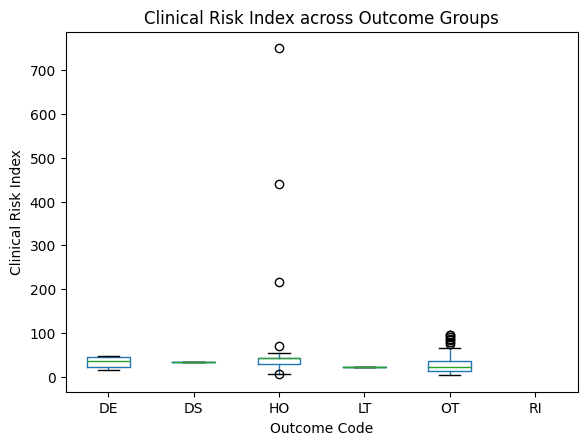

In [252]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

df_patient.boxplot(
    column="clinical_risk_index",
    by="outcome_code",
    grid=False
)

plt.title("Clinical Risk Index across Outcome Groups")
plt.suptitle("")
plt.xlabel("Outcome Code")
plt.ylabel("Clinical Risk Index")

plt.show()

In [253]:
! pip install seaborn
import seaborn as sns

In [254]:
df_standardized["clinical_risk_index"].describe()

count    7.500000e+01
mean    -1.480297e-18
std      1.006734e+00
min     -4.781286e-01
25%     -3.319238e-01
50%     -2.261908e-01
75%     -7.568587e-02
max      7.090122e+00
Name: clinical_risk_index, dtype: float64

In [255]:
df_patient["clinical_risk_index"].describe()

count     75.000000
mean      49.955333
std       99.499499
min        2.700000
25%       17.150000
50%       27.600000
75%       42.475000
max      750.700000
Name: clinical_risk_index, dtype: float64

In [256]:
print(df_patient.shape)
print(df_standardized.shape)

(262, 47)
(262, 47)


In [257]:
print(df_patient["primary_report_id"].nunique())

262


In [258]:
print(df_patient["clinical_risk_index"].isna().sum())

print(df_patient["clinical_risk_index"].notna().sum())

187
75


In [259]:
features = [
    "patient_age",
    "adverse_event_count",
    "outcome_severity_score",
    "burden_index",
    "adverse_event_entropy"
]

df_patient[features].isna().sum().sort_values(ascending=False)

patient_age               59
outcome_severity_score    47
burden_index              47
adverse_event_count        0
adverse_event_entropy      0
dtype: int64

In [260]:
mask = df_patient["clinical_risk_index"].isna()

df_patient.loc[
    mask,
    ["primary_report_id"] + features
].head(20)

,primary_report_id,patient_age,adverse_event_count,outcome_severity_score,burden_index,adverse_event_entropy
9,250881255,69.0,4,4.0,16.0,2.000000
12,252067672,NaN,2,4.0,8.0,1.000000
14,253602502,NaN,1,1.0,1.0,0.000000
15,253961263,67.0,3,4.0,7.5,1.584963
17,254170723,69.0,2,NaN,NaN,1.000000
18,254530823,76.0,4,1.0,10.0,2.000000
21,255155963,7.0,1,4.0,4.0,0.000000
22,256257392,57.0,2,NaN,NaN,1.000000
23,256259643,84.0,6,4.0,24.0,2.584963
24,256981153,71.0,2,1.0,2.0,1.000000


# OBJ 2

In [261]:
print("Total patients:", len(df_patient))

print("\nMissing values:")
print(df_patient[["burden_index",
                  "outcome_severity_score"]].isna().sum())

print("\nPatients available for analysis:")
print(
    df_patient[
        ["burden_index",
         "outcome_severity_score"]
    ].dropna().shape[0]
)

Total patients: 262

Missing values:
burden_index              47
outcome_severity_score    47
dtype: int64

Patients available for analysis:
215


In [262]:
df_patient["outcome_code"].value_counts().sort_index()

outcome_code
DE     14
DS      1
HO     62
LT      3
OT    134
RI      1
Name: count, dtype: int64

In [263]:
df_patient["burden_index"].describe()

count    215.000000
mean       7.566667
std        8.269927
min        1.000000
25%        2.000000
50%        4.000000
75%       10.000000
max       45.500000
Name: burden_index, dtype: float64

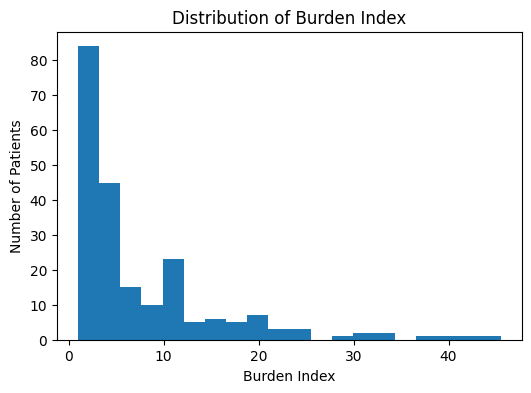

In [264]:
plt.figure(figsize=(6,4))

plt.hist(df_patient["burden_index"].dropna(), bins=20)

plt.xlabel("Burden Index")
plt.ylabel("Number of Patients")
plt.title("Distribution of Burden Index")

plt.show()

In [265]:
analysis_df = df_patient[
    df_patient["outcome_code"].isin(["OT", "HO", "DE"])
].copy()

print(analysis_df["outcome_code"].value_counts())

outcome_code
OT    134
HO     62
DE     14
Name: count, dtype: int64


In [266]:
summary = (
    analysis_df
    .groupby("outcome_code")["burden_index"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
)

summary

,Count,Mean,Median,Std,Min,Max
outcome_code,,,,,,
DE,14,11.773810,11.5,5.161332,6.0,21.0
HO,62,11.830645,10.0,8.183822,2.5,32.5
OT,134,5.182836,3.0,7.772020,1.0,45.5


<Figure size 700x500 with 0 Axes>

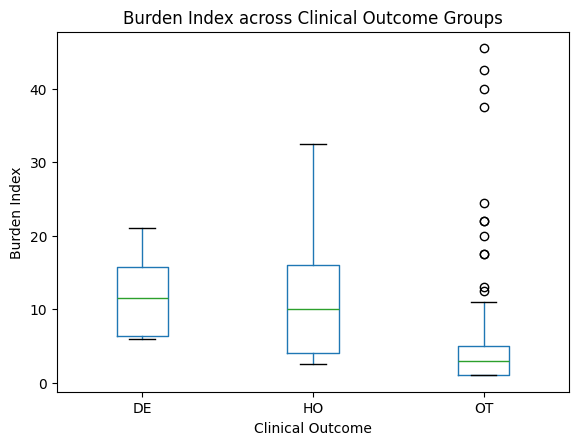

In [267]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

analysis_df.boxplot(
    column="burden_index",
    by="outcome_code",
    grid=False
)

plt.title("Burden Index across Clinical Outcome Groups")
plt.suptitle("")
plt.xlabel("Clinical Outcome")
plt.ylabel("Burden Index")

plt.show()

In [268]:
from scipy.stats import kruskal

OT = analysis_df.loc[
    analysis_df["outcome_code"]=="OT",
    "burden_index"
]

HO = analysis_df.loc[
    analysis_df["outcome_code"]=="HO",
    "burden_index"
]

DE = analysis_df.loc[
    analysis_df["outcome_code"]=="DE",
    "burden_index"
]

H, p = kruskal(OT, HO, DE)

print("Kruskal Statistic =", H)
print("P-value =", p)

Kruskal Statistic = 67.75042664632937
P-value = 1.94169843446176e-15


In [269]:
N = len(analysis_df)
k = 3

epsilon2 = (H - k + 1) / (N - k)

print("Effect Size (ε²):", epsilon2)

Effect Size (ε²): 0.3176349113349245


In [270]:
! pip install scikit-posthocs

In [271]:
import scikit_posthocs as sp

dunn = sp.posthoc_dunn(
    analysis_df,
    val_col="burden_index",
    group_col="outcome_code",
    p_adjust="bonferroni"
)

dunn

,DE,HO,OT
DE,1.000000,1.000000e+00,5.772974e-06
HO,1.000000,1.000000e+00,3.098221e-13
OT,0.000006,3.098221e-13,1.000000e+00


In [272]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    analysis_df["burden_index"],
    analysis_df["outcome_severity_score"]
)

print("Spearman rho =", rho)
print("P-value =", p)

Spearman rho = 0.5668582506232951
P-value = 3.0009735933909e-19


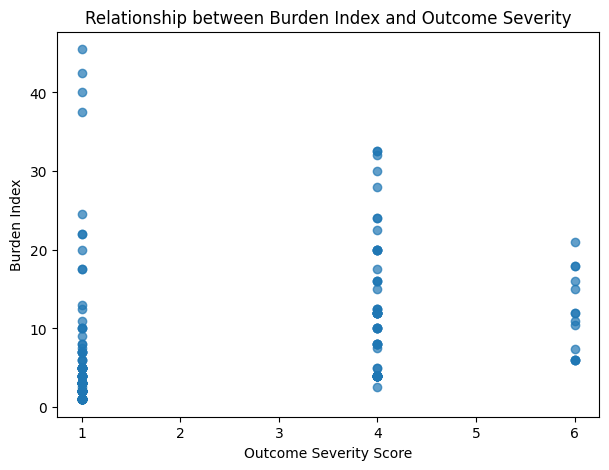

In [273]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.scatter(
    analysis_df["outcome_severity_score"],
    analysis_df["burden_index"],
    alpha=0.7
)

plt.xlabel("Outcome Severity Score")
plt.ylabel("Burden Index")
plt.title("Relationship between Burden Index and Outcome Severity")

plt.show()

for stand

In [274]:
analysis_df = df_standardized[
    df_standardized["outcome_code"].isin(["OT", "HO", "DE"])
].copy()

print(analysis_df["outcome_code"].value_counts())

outcome_code
OT    134
HO     62
DE     14
Name: count, dtype: int64


In [275]:
summary = (
    analysis_df
    .groupby("outcome_code")["burden_index"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
)

print(summary)

              Count      Mean    Median       Std       Min       Max
outcome_code                                                         
DE               14  0.509915  0.476729  0.625565 -0.189884  1.628150
HO               62  0.516804  0.294925  0.991898 -0.614091  3.021976
OT              134 -0.288926 -0.553490  0.941986 -0.795895  4.597605


<Figure size 700x500 with 0 Axes>

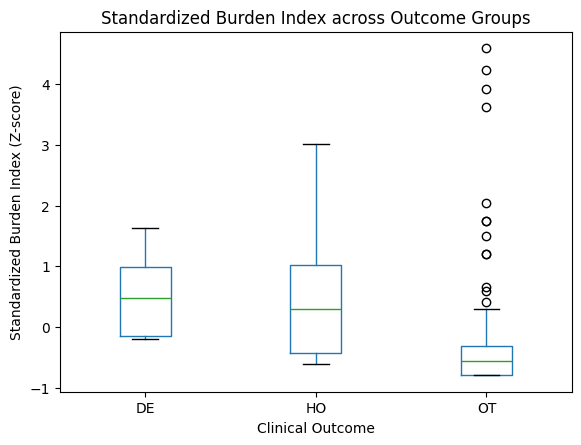

In [276]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

analysis_df.boxplot(
    column="burden_index",
    by="outcome_code",
    grid=False
)

plt.title("Standardized Burden Index across Outcome Groups")
plt.suptitle("")

plt.xlabel("Clinical Outcome")
plt.ylabel("Standardized Burden Index (Z-score)")

plt.show()

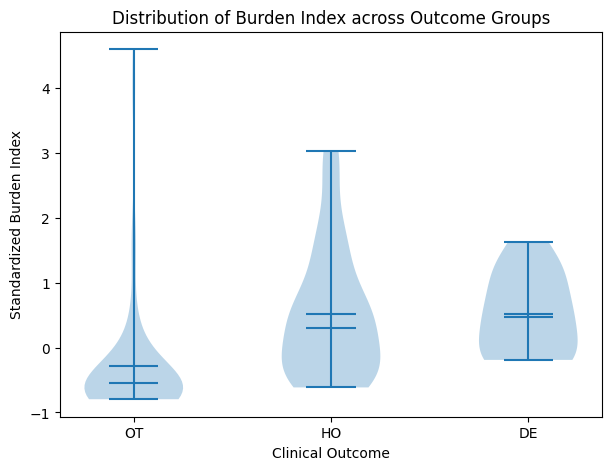

In [277]:
import matplotlib.pyplot as plt

groups = [
    analysis_df.loc[analysis_df["outcome_code"]=="OT","burden_index"],
    analysis_df.loc[analysis_df["outcome_code"]=="HO","burden_index"],
    analysis_df.loc[analysis_df["outcome_code"]=="DE","burden_index"]
]

plt.figure(figsize=(7,5))

plt.violinplot(
    groups,
    showmeans=True,
    showmedians=True
)

plt.xticks([1,2,3],["OT","HO","DE"])

plt.xlabel("Clinical Outcome")
plt.ylabel("Standardized Burden Index")

plt.title("Distribution of Burden Index across Outcome Groups")

plt.show()

In [278]:
from scipy.stats import kruskal

OT = analysis_df.loc[
    analysis_df["outcome_code"]=="OT",
    "burden_index"
]

HO = analysis_df.loc[
    analysis_df["outcome_code"]=="HO",
    "burden_index"
]

DE = analysis_df.loc[
    analysis_df["outcome_code"]=="DE",
    "burden_index"
]

H, p = kruskal(OT, HO, DE)

print("Kruskal Statistic :", round(H,3))
print("P-value :", p)

Kruskal Statistic : 67.75
P-value : 1.94169843446176e-15


In [279]:
N = len(analysis_df)
k = 3

epsilon_squared = (H - k + 1) / (N - k)

print("Effect Size (ε²):", round(epsilon_squared,4))

Effect Size (ε²): 0.3176


In [280]:
dunn = sp.posthoc_dunn(
    analysis_df,
    val_col="burden_index",
    group_col="outcome_code",
    p_adjust="bonferroni"
)

print(dunn)

          DE            HO            OT
DE  1.000000  1.000000e+00  5.772974e-06
HO  1.000000  1.000000e+00  3.098221e-13
OT  0.000006  3.098221e-13  1.000000e+00


In [281]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    analysis_df["burden_index"],
    analysis_df["outcome_severity_score"]
)

print("Spearman rho :", round(rho,3))
print("P-value :", p)

Spearman rho : 0.567
P-value : 3.0009735933909e-19


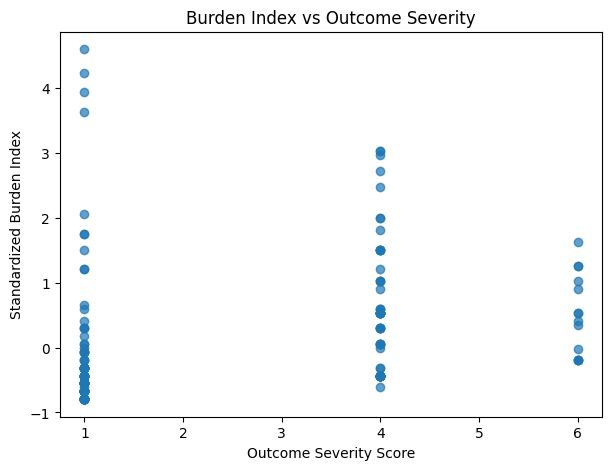

In [282]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,5))

plt.scatter(
    analysis_df["outcome_severity_score"],
    analysis_df["burden_index"],
    alpha=0.7
)

plt.xlabel("Outcome Severity Score")
plt.ylabel("Standardized Burden Index")

plt.title("Burden Index vs Outcome Severity")

plt.show()

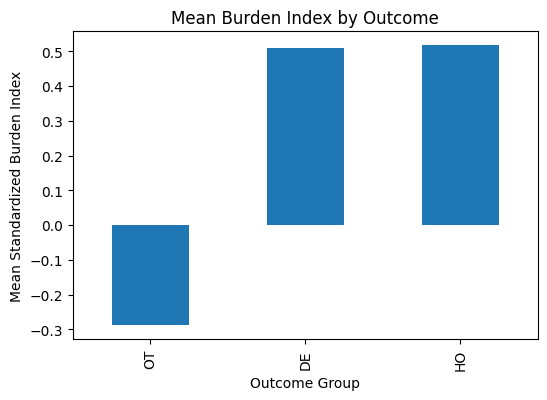

In [283]:
mean_burden = (
    analysis_df
    .groupby("outcome_code")["burden_index"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(6,4))

mean_burden.plot(kind="bar")

plt.ylabel("Mean Standardized Burden Index")
plt.xlabel("Outcome Group")
plt.title("Mean Burden Index by Outcome")

plt.show()

# RISK CLASSIFICATION BTW PATIENTS

In [285]:
risk_mapping = {
    "DE": 1,   # Death
    "HO": 1,   # Hospitalization
    "LT": 1,   # Life-threatening
    "DS": 1,   # Disability

    "OT": 0,   # Other serious
    "RI": 0    # Required intervention
}

In [286]:
# Define the mapping
risk_mapping = {
    "DE": "High Risk",      # Death
    "HO": "High Risk",      # Hospitalization
    "LT": "High Risk",      # Life-threatening
    "DS": "High Risk",      # Disability
    "OT": "Low Risk",       # Other
    "RI": "Low Risk"        # Required intervention
}

# Create a new column
df_standardized["risk_class"] = df_standardized["outcome_code"].map(risk_mapping)

In [287]:
print(df_standardized.columns.tolist())

['primary_report_id', 'case_id_drug', 'drug_sequence_number', 'drug_role_code', 'dose_description', 'dechallenge_status', 'rechallenge_status', 'new_drug_application_number', 'dose_amount', 'dose_unit', 'case_id_demographics', 'case_version', 'initial_followup_code', 'adverse_event_date', 'manufacturer_received_date', 'initial_fda_received_date', 'latest_fda_received_date', 'report_type_code', 'patient_age', 'age_unit', 'age_group', 'patient_sex', 'electronic_submission', 'patient_weight', 'weight_unit', 'report_date', 'reporter_occupation', 'case_id', 'preferred_term_adverse_event', 'outcome_code', 'indication', 'therapy_start_date', 'therapy_end_date', 'therapy_duration', 'outcome_severity_score', 'overall_treatment_duration', 'overall_therapy_start_date', 'latency_days', 'dose_amount_standardized', 'dose_unit_standardized', 'dose_per_kg_mg', 'dose_per_kg_mg_m2', 'adverse_event_count', 'burden_index', 'adverse_event_entropy', 'clinical_risk_index', 'composite_clinical_risk_index', 'r

In [288]:
risk_mapping = {
    "Low Risk": 0,
    "High Risk": 1
}

df_standardized["risk_class"] = df_standardized["risk_class"].map(risk_mapping)

In [289]:
analysis_df = df_standardized[
    ["composite_clinical_risk_index", "risk_class"]
].dropna()

low_risk = analysis_df.loc[
    analysis_df["risk_class"] == 0,
    "composite_clinical_risk_index"
]

high_risk = analysis_df.loc[
    analysis_df["risk_class"] == 1,
    "composite_clinical_risk_index"
]

print("Low Risk patients :", len(low_risk))
print("High Risk patients:", len(high_risk))

Low Risk patients : 58
High Risk patients: 41


# MANWHITE NEY

COMPOSITE CLINICAL RISK VS HIGH/LOW RISKK

In [292]:
from scipy.stats import mannwhitneyu

stat, p = mannwhitneyu(
    low_risk,
    high_risk,
    alternative="two-sided"
)

print(f"U Statistic : {stat:.2f}")
print(f"P-value     : {p:.6f}")

if p < 0.05:
    print("✅ Significant difference between the two groups.")
else:
    print("❌ No significant difference.")

U Statistic : 535.50
P-value     : 0.000003
✅ Significant difference between the two groups.


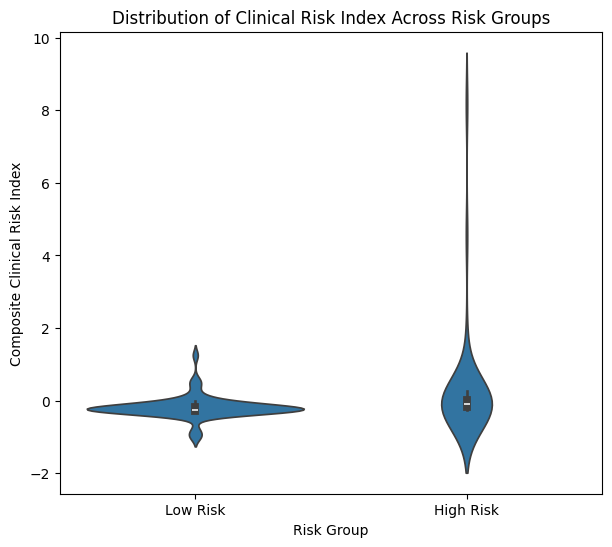

In [293]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,6))

sns.violinplot(
    data=analysis_df,
    x="risk_class",
    y="composite_clinical_risk_index",
    inner="box"
)

plt.xticks([0,1], ["Low Risk","High Risk"])
plt.xlabel("Risk Group")
plt.ylabel("Composite Clinical Risk Index")
plt.title("Distribution of Clinical Risk Index Across Risk Groups")

plt.show()

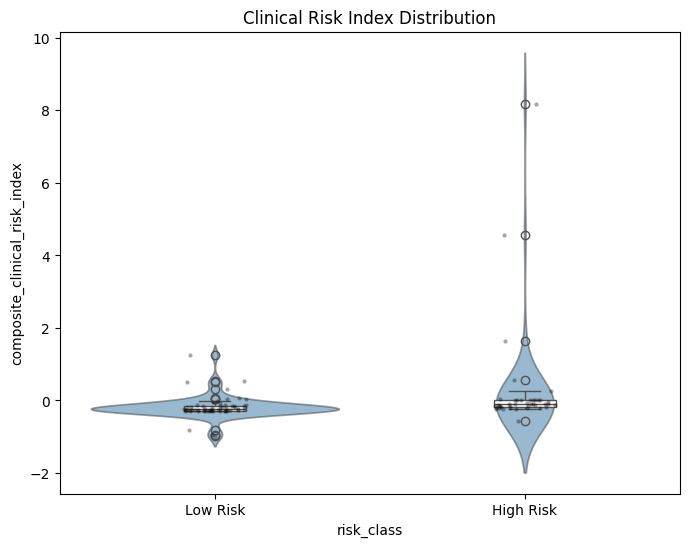

In [294]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,6))

sns.violinplot(
    data=analysis_df,
    x="risk_class",
    y="composite_clinical_risk_index",
    inner=None,
    alpha=0.5
)

sns.stripplot(
    data=analysis_df,
    x="risk_class",
    y="composite_clinical_risk_index",
    color="black",
    alpha=0.35,
    size=3
)

sns.boxplot(
    data=analysis_df,
    x="risk_class",
    y="composite_clinical_risk_index",
    width=0.2,
    showcaps=True,
    boxprops={"facecolor":"white"}
)

plt.xticks([0,1],["Low Risk","High Risk"])
plt.title("Clinical Risk Index Distribution")

plt.show()

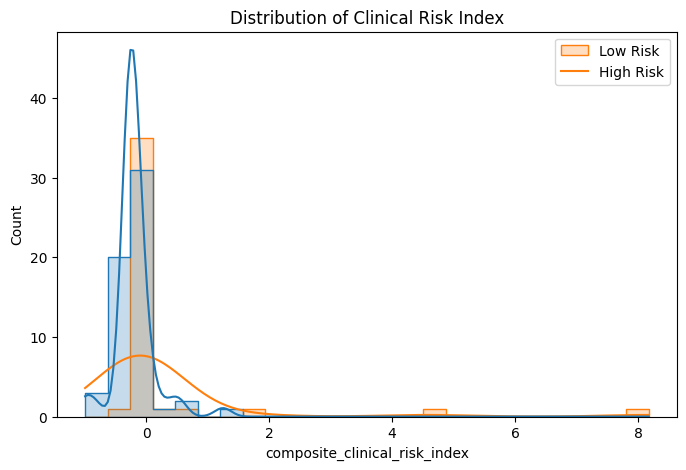

In [295]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=analysis_df,
    x="composite_clinical_risk_index",
    hue="risk_class",
    bins=25,
    kde=True,
    element="step"
)

plt.legend(["Low Risk","High Risk"])
plt.title("Distribution of Clinical Risk Index")

plt.show()

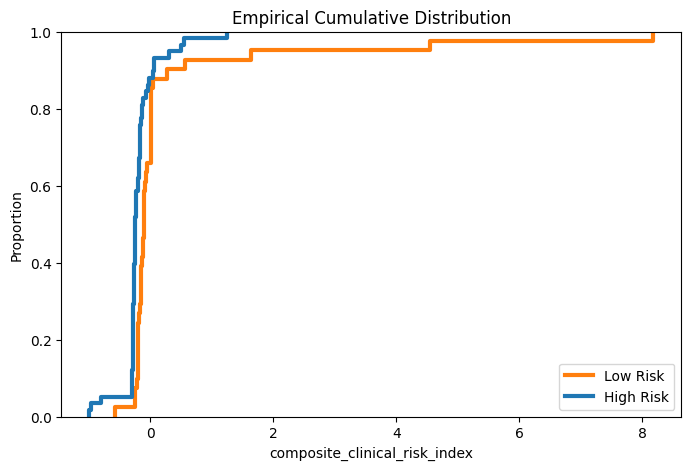

In [296]:
plt.figure(figsize=(8,5))

sns.ecdfplot(
    data=analysis_df,
    x="composite_clinical_risk_index",
    hue="risk_class",
    linewidth=3
)

plt.legend(["Low Risk","High Risk"])
plt.title("Empirical Cumulative Distribution")

plt.show()

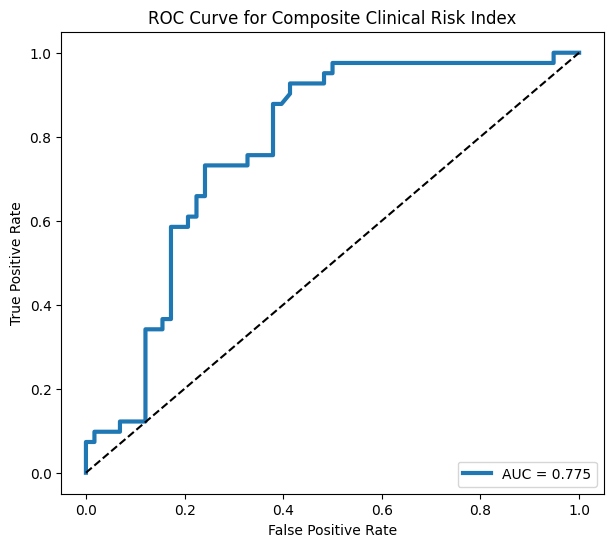

AUC = 0.775


In [297]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Remove missing values
roc_df = df_standardized[
    ["risk_class", "composite_clinical_risk_index"]
].dropna()

y_true = roc_df["risk_class"]
y_score = roc_df["composite_clinical_risk_index"]

# ROC
fpr, tpr, thresholds = roc_curve(y_true, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(fpr, tpr,
         linewidth=3,
         label=f"AUC = {roc_auc:.3f}")

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for Composite Clinical Risk Index")
plt.legend(loc="lower right")

plt.show()

print(f"AUC = {roc_auc:.3f}")

In [298]:
import statsmodels.api as sm

log_df = df_standardized[
    ["risk_class","composite_clinical_risk_index"]
].dropna()

X = sm.add_constant(log_df["composite_clinical_risk_index"])
y = log_df["risk_class"]

model = sm.Logit(y, X)
result = model.fit()

print(result.summary())

Optimization terminated successfully.
         Current function value: 0.637156
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:             risk_class   No. Observations:                   99
Model:                          Logit   Df Residuals:                       97
Method:                           MLE   Df Model:                            1
Date:                Sat, 10 Oct 2026   Pseudo R-squ.:                 0.06070
Time:                        22:47:13   Log-Likelihood:                -63.078
converged:                       True   LL-Null:                       -67.155
Covariance Type:            nonrobust   LLR p-value:                  0.004300
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                            -0.1929      0.241     -0.801      0.

In [299]:
from scipy.stats import pointbiserialr

corr, p = pointbiserialr(
    log_df["risk_class"],
    log_df["composite_clinical_risk_index"]
)

print("Correlation :", corr)
print("P-value :", p)

Correlation : 0.2216050197650141
P-value : 0.027494502122221567


# Feature Interaction Network

In [300]:
features = [
    "patient_age",
    "latency_days",
    "burden_index",
    "adverse_event_entropy",
    "overall_treatment_duration"
]

network_df = df_standardized[features].dropna()

corr = network_df.corr(method="spearman")

display(corr)

,patient_age,latency_days,burden_index,adverse_event_entropy,overall_treatment_duration
patient_age,1.000000,0.062206,0.262845,0.010381,0.302947
latency_days,0.062206,1.000000,-0.092415,-0.309502,0.525516
burden_index,0.262845,-0.092415,1.000000,0.787459,0.381846
adverse_event_entropy,0.010381,-0.309502,0.787459,1.000000,0.262216
overall_treatment_duration,0.302947,0.525516,0.381846,0.262216,1.000000


In [301]:
! pip install networkx

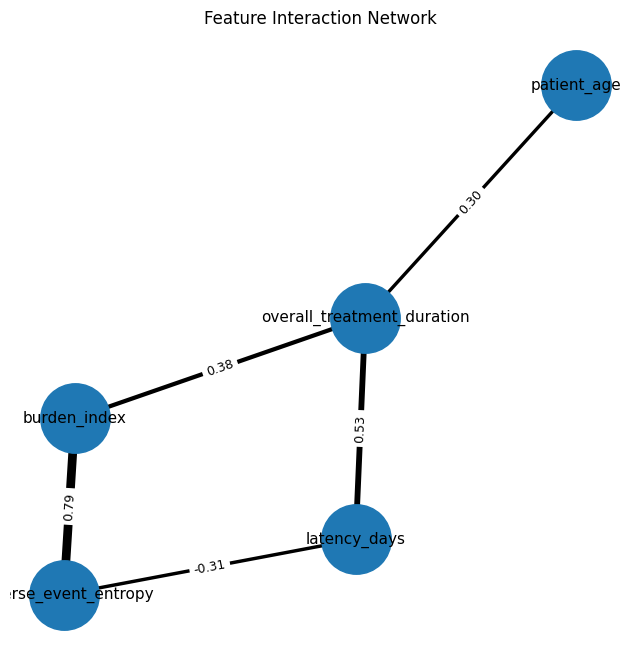

In [302]:
import networkx as nx
import matplotlib.pyplot as plt

threshold = 0.30

G = nx.Graph()

for feature in corr.columns:
    G.add_node(feature)

for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        value = corr.iloc[i, j]

        if abs(value) >= threshold:
            G.add_edge(
                corr.columns[i],
                corr.columns[j],
                weight=abs(value),
                corr=value
            )

plt.figure(figsize=(8,8))

pos = nx.spring_layout(G, seed=42)

weights = [
    G[u][v]["weight"] * 8
    for u, v in G.edges()
]

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=2500
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=11
)

nx.draw_networkx_edges(
    G,
    pos,
    width=weights
)

edge_labels = {
    (u, v): f"{d['corr']:.2f}"
    for u, v, d in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9
)

plt.title("Feature Interaction Network")

plt.axis("off")
plt.show()

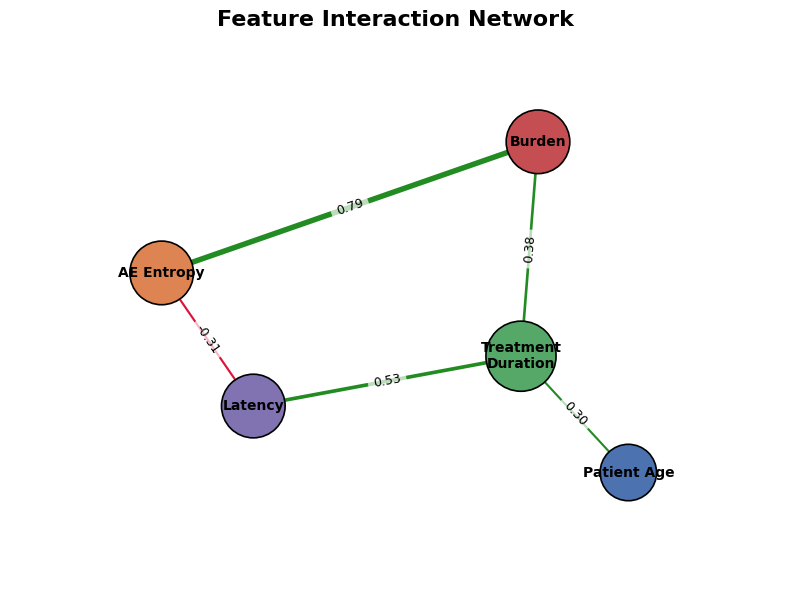

,Degree Centrality
overall_treatment_duration,0.75
latency_days,0.50
burden_index,0.50
adverse_event_entropy,0.50
patient_age,0.25


In [303]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# -------------------------------------------------------
# Features
# -------------------------------------------------------

features = [
    "patient_age",
    "latency_days",
    "burden_index",
    "adverse_event_entropy",
    "overall_treatment_duration"
]

network_df = df_standardized[features].dropna()

corr = network_df.corr(method="spearman")

# -------------------------------------------------------
# Build Network
# -------------------------------------------------------

threshold = 0.30

G = nx.Graph()

for feature in corr.columns:
    G.add_node(feature)

for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):

        r = corr.iloc[i, j]

        if abs(r) >= threshold:
            G.add_edge(
                corr.columns[i],
                corr.columns[j],
                weight=abs(r),
                corr=r
            )

# -------------------------------------------------------
# Degree Centrality
# -------------------------------------------------------

centrality = nx.degree_centrality(G)

# Smaller node sizes
node_sizes = [
    1200 + centrality[node] * 1800
    for node in G.nodes()
]

# -------------------------------------------------------
# Better Layout
# -------------------------------------------------------

pos = nx.kamada_kawai_layout(G)

# Shift everything slightly right so labels aren't clipped
for node in pos:
    pos[node][0] += 0.15

# -------------------------------------------------------
# Edge properties
# -------------------------------------------------------

edge_colors = [
    "forestgreen" if G[u][v]["corr"] > 0 else "crimson"
    for u, v in G.edges()
]

edge_widths = [
    G[u][v]["weight"] * 5
    for u, v in G.edges()
]

# -------------------------------------------------------
# Node colors
# -------------------------------------------------------

node_colors = []

for node in G.nodes():

    if node == "patient_age":
        node_colors.append("#4C72B0")

    elif node == "overall_treatment_duration":
        node_colors.append("#55A868")

    elif node == "latency_days":
        node_colors.append("#8172B2")

    elif node == "burden_index":
        node_colors.append("#C44E52")

    elif node == "adverse_event_entropy":
        node_colors.append("#DD8452")

# -------------------------------------------------------
# Short labels (display only)
# -------------------------------------------------------

labels = {
    "patient_age": "Patient Age",
    "latency_days": "Latency",
    "burden_index": "Burden",
    "adverse_event_entropy": "AE Entropy",
    "overall_treatment_duration": "Treatment\nDuration"
}

# -------------------------------------------------------
# Plot
# -------------------------------------------------------

plt.figure(figsize=(8,6))

nx.draw_networkx_nodes(
    G,
    pos,
    node_size=node_sizes,
    node_color=node_colors,
    edgecolors="black",
    linewidths=1.2
)

nx.draw_networkx_edges(
    G,
    pos,
    edge_color=edge_colors,
    width=edge_widths
)

nx.draw_networkx_labels(
    G,
    pos,
    labels=labels,
    font_size=10,
    font_weight="bold"
)

edge_labels = {
    (u, v): f"{d['corr']:.2f}"
    for u, v, d in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9,
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.7)
)

plt.title(
    "Feature Interaction Network",
    fontsize=16,
    fontweight="bold"
)

plt.margins(0.25)
plt.axis("off")
plt.tight_layout()
plt.show()

# -------------------------------------------------------
# Degree Centrality
# -------------------------------------------------------

centrality_df = (
    pd.DataFrame.from_dict(
        centrality,
        orient="index",
        columns=["Degree Centrality"]
    )
    .sort_values("Degree Centrality", ascending=False)
)

display(centrality_df)

Predictors of Severe Outcome


In [304]:
from sklearn.model_selection import train_test_split

features = [
    "overall_treatment_duration",
    "latency_days",
    "burden_index",
    "adverse_event_entropy",
    "clinical_risk_index",
    "composite_clinical_risk_index",
    "dose_per_kg_mg",
    "dose_per_kg_mg_m2",
    "adverse_event_count"
]

target = "outcome_severity_score"

analysis_df = df_standardized[
    features + [target]
].dropna()

X = analysis_df[features]
y = analysis_df[target]

print(X.shape)

(0, 9)


In [305]:
from sklearn.impute import SimpleImputer

features = [
    "overall_treatment_duration",
    "latency_days",
    "burden_index",
    "adverse_event_entropy",
    "clinical_risk_index",
    "composite_clinical_risk_index",
    "dose_per_kg_mg",
    "dose_per_kg_mg_m2",
    "adverse_event_count"
]

target = "outcome_severity_score"

analysis_df = df_standardized[
    features + [target]
].copy()

# Remove only rows where target is missing
analysis_df = analysis_df.dropna(subset=[target])

print("Remaining rows:", len(analysis_df))

Remaining rows: 215


In [306]:
from sklearn.impute import SimpleImputer

X = analysis_df[features]
y = analysis_df[target]

imputer = SimpleImputer(strategy="median")

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=features
)

In [307]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

rf.fit(X, y)

,n_estimators,500
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [308]:
importance_df = (
    pd.DataFrame({
        "Feature": features,
        "Importance": rf.feature_importances_
    })
    .sort_values("Importance", ascending=False)
)

display(importance_df)

,Feature,Importance
2,burden_index,0.519198
3,adverse_event_entropy,0.178492
8,adverse_event_count,0.152877
5,composite_clinical_risk_index,0.032223
7,dose_per_kg_mg_m2,0.029767
1,latency_days,0.029660
4,clinical_risk_index,0.023154
6,dose_per_kg_mg,0.022726
0,overall_treatment_duration,0.011903


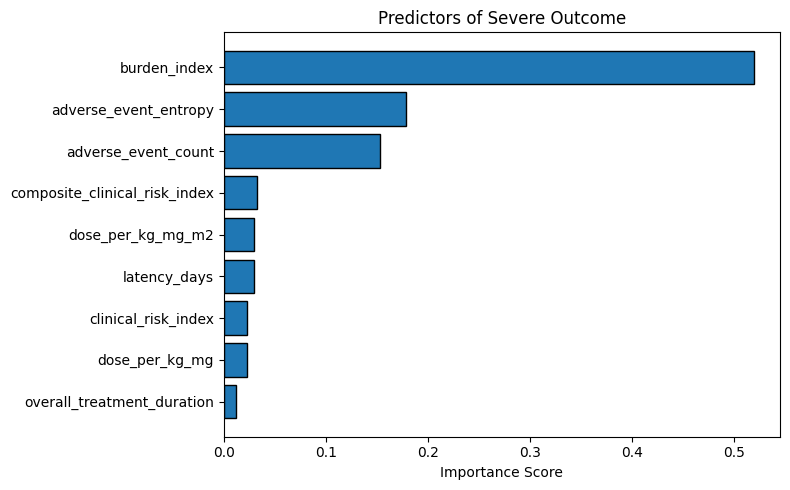

In [309]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    edgecolor="black"
)

plt.gca().invert_yaxis()

plt.xlabel("Importance Score")
plt.title("Predictors of Severe Outcome")

plt.tight_layout()

plt.show()

In [310]:
from scipy.stats import spearmanr

analysis_df = df_standardized[
    ["dose_amount_standardized", "outcome_severity_score"]
].dropna()

rho, p = spearmanr(
    analysis_df["dose_amount_standardized"],
    analysis_df["outcome_severity_score"]
)

print(f"Spearman Correlation : {rho:.3f}")
print(f"P-value : {p:.5f}")

Spearman Correlation : 0.002
P-value : 0.98787
